# Численное дифференцирование

Абсолютная погрешность пяти разностных формул при $h_n=2/2^n$, $n=1,\ldots,21$.

В условии не указана точка вычисления производной, поэтому ниже принято $x_0=10$. Её можно изменить в ячейке с параметрами.

In [41]:
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np

In [42]:
x0 = 1.0
n = np.linspace(1, 22, 1000)
h_values = 2.0 / 2.0**n

## Формулы производных

In [43]:
Function = Callable[[float | np.ndarray], float | np.ndarray]

def method_1(f: Function, x: float, h: float) -> float:
    return (f(x + h) - f(x)) / h

method_1_label = r"$\frac{f(x + h) - f(x)}{h}$"

def method_2(f: Function, x: float, h: float) -> float:
    return (f(x) - f(x - h)) / h

method_2_label = r"$\frac{f(x) - f(x - h)}{h}$"

def method_3(f: Function, x: float, h: float) -> float:
    return (f(x + h) - f(x - h)) / (2.0 * h)

method_3_label = r"$\frac{f(x + h) - f(x - h)}{2h}$"

def method_4(f: Function, x: float, h: float) -> float:
    return (4.0 / 3.0) * method_3(f, x, h) - (1.0 / 3.0) * method_3(f, x, 2.0 * h)

method_4_label = r"$\frac{4}{3} \frac{f(x + h) - f(x - h)}{h} - \frac{1}{3} \frac{f(x + 2h) - f(x - 2h)}{2h}$"

def method_5(f: Function, x: float, h: float) -> float:
    return (3.0 / 2.0) * method_3(f, x, h) - (3.0 / 5.0) * method_3(f, x, 2.0 * h) + (1.0 / 10.0) * method_3(f, x, 3.0 * h)

method_5_label = r"$\frac{3}{2} \frac{f(x + h) - f(x - h)}{h} - \frac{3}{5} \frac{f(x + 2h) - f(x - 2h)}{2h} + \frac{1}{10} \frac{f(x + 3h) - f(x - 3h)}{3h}$"

METHODS = [(method_1, method_1_label),
           (method_2, method_2_label),
           (method_3, method_3_label),
           (method_4, method_4_label),
           (method_5, method_5_label)]

## Функции и их аналитические производные

In [44]:
#
# f (x) = sin(x^2)
# f'(x) = 2x cos(x^2)
#
def func_1(x):
    return np.sin(x**2)

def der_1(x):
    return 2.0 * x * np.cos(x**2)

func_1_name = r"$\sin(x^2)$"

#
# f (x) = cos(sin(x))
# f'(x) = -sin(sin(x)) * cos(x)
#
def func_2(x):
    return np.cos(np.sin(x))

def der_2(x):
    return -np.cos(x) * np.sin(np.sin(x))

func_2_name = r"$\cos(\sin(x))$"

#
# f (x) = exp(sin(cos(x)))
# f'(x) = exp(sin(cos(x))) * cos(cos(x)) * (-sin(x))
#
def func_3(x):
    return np.exp(np.sin(np.cos(x)))

def der_3(x):
    return -func_3(x) * np.cos(np.cos(x)) * np.sin(x)

func_3_name = r"$\exp(\sin(\cos(x)))$"

#
# f (x) = ln(x + 3)
# f'(x) = 1/(x + 3)
#
def func_4(x):
    return np.log(x + 3.0)

def der_4(x):
    return 1 / (x + 3.0)

func_4_name = r"$\ln(x + 3)$"

#
# f (x) = (x + 3)^0.5 = sqrt(x + 3)
# f'(x) = 0.5 / sqrt(x + 3)
#
def func_5(x):
    return np.sqrt(x + 3.0)

def der_5(x):
    return 0.5 / np.sqrt(x + 3.0)

func_5_name = r"$(x + 3)^{0.5}$"

FUNCTIONS = [(func_1, der_1, func_1_name),
             (func_2, der_2, func_2_name),
             (func_3, der_3, func_3_name),
             (func_4, der_4, func_4_name),
             (func_5, der_5, func_5_name)]



## Графики абсолютной погрешности

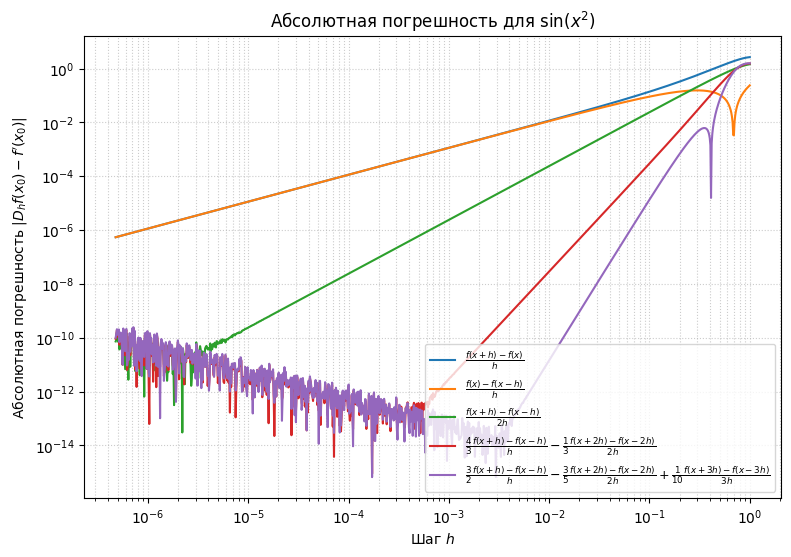

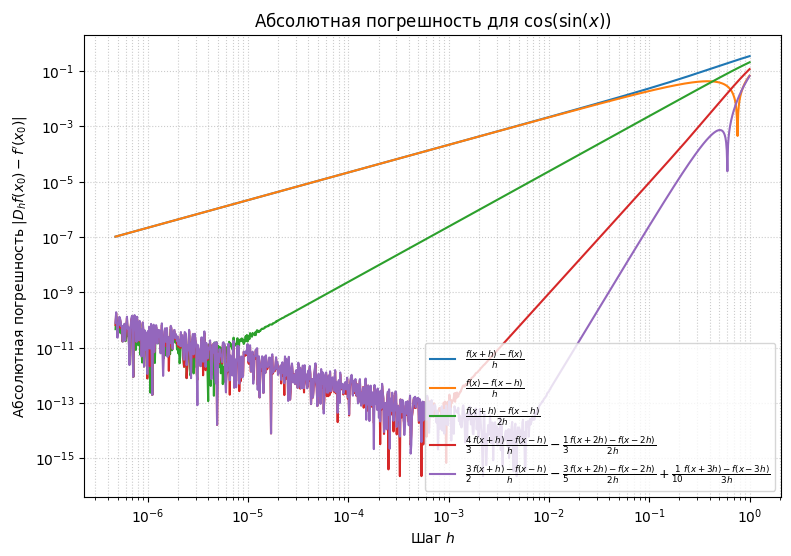

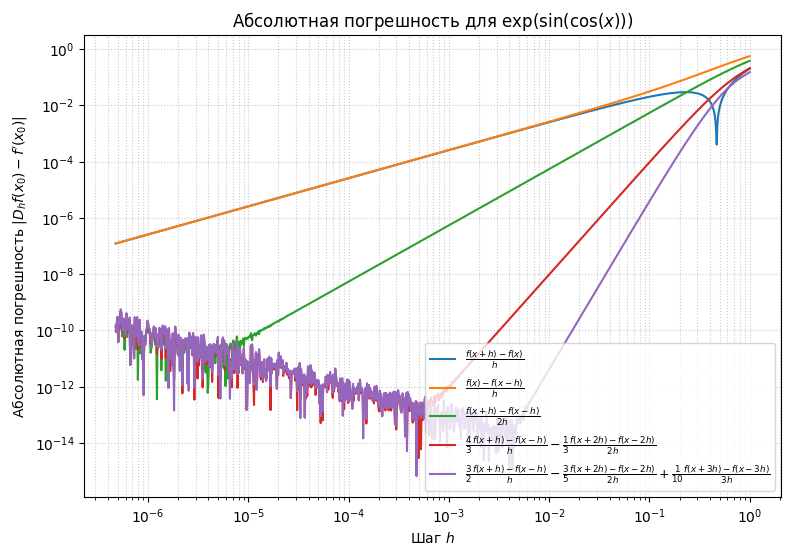

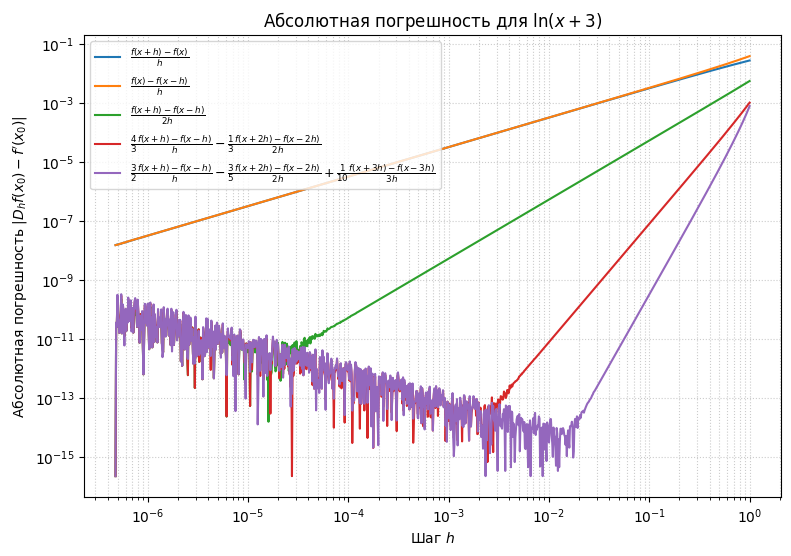

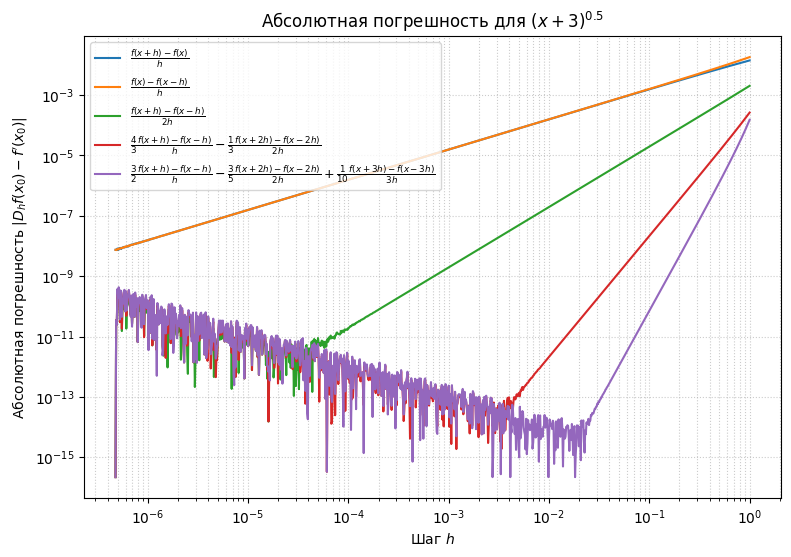

In [45]:
saved_plots = []

for (func, der, func_name) in FUNCTIONS:
    exact = der(x0)
    plt.figure(figsize=(9, 6))

    for (method, label) in METHODS:
        approx = np.array([method(func, x0, h) for h in h_values])
        abs_errors = np.abs(approx - exact)
        visible_errors = np.maximum(abs_errors, np.finfo(float).eps)
        plt.loglog(h_values, visible_errors, linewidth=1.5, label=label)

    # ax.set_title(f"Абсолютная погрешность для {function_name} при $x_0={x0:g}$")
    plt.title(f"Абсолютная погрешность для {func_name}")
    plt.xlabel(r"Шаг $h$")
    plt.ylabel(r"Абсолютная погрешность $|D_h f(x_0) - f'(x_0)|$")
    plt.grid(True, which="both", linestyle=":", alpha=0.65)
    plt.legend(fontsize=9)
    plt.show()